# MOT Temperature (time of flight)

Python companion to the AMO Toolkit page [MOT Temperature (time of flight)](https://amotoolkit.com/pages/tof-calculator.html). It reproduces the page's calculator with the same constants and formulas, so you can change anything, script a scan, or check a number in your own analysis.

[Open in Colab](https://colab.research.google.com/github/saumitraphatak/amo-career/blob/main/notebooks/tof-calculator.ipynb) · needs only `numpy`, `scipy` and `matplotlib`.

## 1. Constants and species
The page's rounded constants and species table.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

kB, hbar, h, amu = 1.380649e-23, 1.054572e-34, 6.626070e-34, 1.660539e-27
ATOMS = {
    "Rb87": (86.909, 6.065, 780.241), "Rb85": (84.912, 6.065, 780.241), "Cs133": (132.905, 5.234, 852.347),
    "Li6": (6.015, 5.8724, 670.977), "Li7": (7.016, 5.8724, 670.977), "Na23": (22.990, 9.795, 588.996),
    "K39": (38.964, 6.035, 766.701), "K40": (39.964, 6.035, 766.701),
}   # mass (u), Γ/2π (MHz), λ (nm)

## 2. A cloud at temperature T
Ballistic expansion $\sigma^2(t) = \sigma_0^2 + (k_BT/m)\,t^2$; thermal de Broglie wavelength $\lambda_{dB} = h/\sqrt{2\pi m k_BT}$; peak density of an isotropic Gaussian $n_0 = N/[(2\pi)^{3/2}\sigma_0^3]$; phase-space density $n_0\lambda_{dB}^3$.

In [2]:
def cloud(species="Rb87", T=1e-6, sigma0_um=10.0, N=1e4, trap_Hz=100.0):
    m_u, G_MHz, lam_nm = ATOMS[species]
    m = m_u * amu
    lam_dB = h / np.sqrt(2 * np.pi * m * kB * T)
    n0 = N / (2 * np.pi) ** 1.5 / (sigma0_um * 1e-6) ** 3
    k = 2 * np.pi / (lam_nm * 1e-9)
    return dict(
        v_rms_mm_s=np.sqrt(kB * T / m) * 1e3,
        lambda_dB_nm=lam_dB * 1e9,
        PSD=n0 * lam_dB**3,
        n_peak_cm3=n0 * 1e-6,
        T_Doppler_uK=hbar * 2 * np.pi * G_MHz * 1e6 / (2 * kB) * 1e6,
        T_recoil_nK=hbar**2 * k**2 / (2 * m * kB) * 1e9,
        sigma_trap_um=np.sqrt(kB * T / (m * (2 * np.pi * trap_Hz) ** 2)) * 1e6,
    )

def sigma_um(t_ms, species="Rb87", T=1e-6, sigma0_um=10.0):
    m = ATOMS[species][0] * amu
    return np.sqrt((sigma0_um * 1e-6) ** 2 + kB * T / m * (np.asarray(t_ms) * 1e-3) ** 2) * 1e6

r = cloud()     # page defaults: Rb-87, 1 µK, σ0 = 10 µm, N = 10^4, 100 Hz trap
for key, v in r.items():
    print(f"{key:>14} = {v:.4g}")

    v_rms_mm_s = 9.781
  lambda_dB_nm = 187.3
           PSD = 0.00417
    n_peak_cm3 = 6.349e+11
  T_Doppler_uK = 145.5
   T_recoil_nK = 181
 sigma_trap_um = 15.57

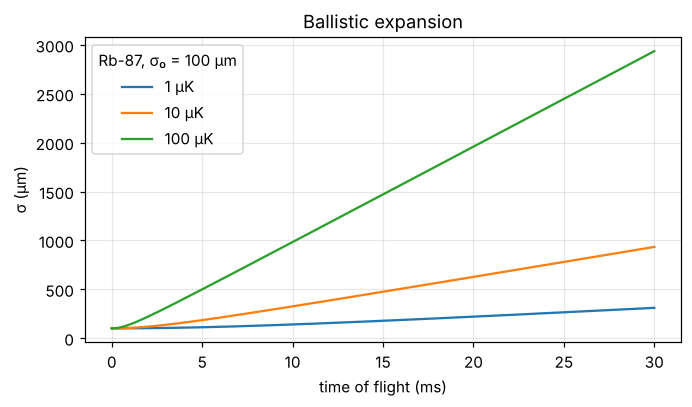

In [3]:
t = np.linspace(0, 30, 200)
for T in (1e-6, 10e-6, 100e-6):
    plt.plot(t, sigma_um(t, T=T, sigma0_um=100), label=f"{T*1e6:g} µK")
plt.xlabel("time of flight (ms)"); plt.ylabel("σ (µm)"); plt.legend(title="Rb-87, σ₀ = 100 µm"); plt.title("Ballistic expansion")

## 3. Fit a temperature from data
The page fits $\sigma^2$ against $t^2$ with a straight line: the slope is $k_BT/m$ and the intercept $\sigma_0^2$. These are the page's five example points. `np.polyfit` also gives the uncertainty, which the page does not show.

T = 1.983 ± 0.015 µK,  σ0 = 17.8 µm,  R² = 0.9998

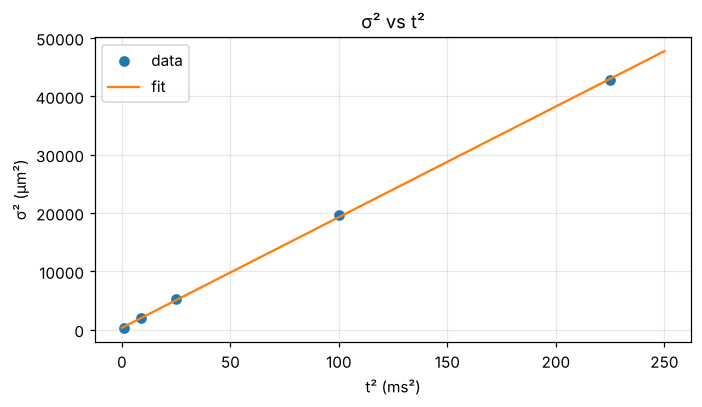

In [4]:
t_ms = np.array([1, 3, 5, 10, 15.0])
s_um = np.array([15, 45, 72, 140, 207.0])
(b, a), cov = np.polyfit(t_ms**2, s_um**2, 1, cov=True)
m = ATOMS["Rb87"][0] * amu
T_fit = b * 1e-6 * m / kB                 # µm²/ms² -> m²/s²
dT = np.sqrt(cov[0, 0]) * 1e-6 * m / kB
resid = s_um**2 - (a + b * t_ms**2)
R2 = 1 - np.sum(resid**2) / np.sum((s_um**2 - np.mean(s_um**2)) ** 2)
fit = dict(T_fit_uK=T_fit * 1e6, sigma0_fit_um=np.sqrt(a) if a > 0 else 0.0, slope=b, R2=R2)
print(f"T = {T_fit*1e6:.3f} ± {dT*1e6:.3f} µK,  σ0 = {fit['sigma0_fit_um']:.1f} µm,  R² = {R2:.4f}")
x = np.linspace(0, 250, 50)
plt.plot(t_ms**2, s_um**2, "o", label="data"); plt.plot(x, a + b * x, label="fit")
plt.xlabel("t² (ms²)"); plt.ylabel("σ² (µm²)"); plt.legend(); plt.title("σ² vs t²")

**Try it:** short times constrain σ₀, long times constrain T. Drop the 15 ms point and see how much the temperature uncertainty grows.

## 4. Check against the page
Values the page shows at its defaults, read from the live page when this notebook was built.

In [5]:
def check(ours, page, rel=0.006):
    """Compare our numbers with the values the web page shows at its default settings."""
    bad = []
    for k, shown in page.items():
        v = ours[k]
        ok = abs(v - shown) <= rel * abs(shown) + 1e-12 or abs(v - shown) <= 0.5 * 10 ** -DECIMALS.get(k, 99)
        print(f"{k:>12}: notebook {v:<12.4g} page {shown:<10g} {'OK' if ok else 'MISMATCH'}")
        if not ok: bad.append(k)
    assert not bad, f"differs from the page: {bad}"
    print("All values match the page.")

ours = {**r, **fit}
DECIMALS = dict(sigma0_fit_um=1, R2=4)
page = dict(v_rms_mm_s=9.781, lambda_dB_nm=187.3, PSD=4.17e-3, n_peak_cm3=6.349e11, T_Doppler_uK=145.5,
            T_recoil_nK=181.0, sigma_trap_um=15.57, T_fit_uK=1.983, sigma0_fit_um=17.8, slope=189.6956, R2=0.9998)
check(ours, page)

  v_rms_mm_s: notebook 9.781        page 9.781      OK
lambda_dB_nm: notebook 187.3        page 187.3      OK
         PSD: notebook 0.00417      page 0.00417    OK
  n_peak_cm3: notebook 6.349e+11    page 6.349e+11  OK
T_Doppler_uK: notebook 145.5        page 145.5      OK
 T_recoil_nK: notebook 181          page 181        OK
sigma_trap_um: notebook 15.57        page 15.57      OK
    T_fit_uK: notebook 1.983        page 1.983      OK
sigma0_fit_um: notebook 17.85        page 17.8       OK
       slope: notebook 189.7        page 189.696    OK
          R2: notebook 0.9998       page 0.9998     OK
All values match the page.